# 13.4 USDA Food Database

Bộ Nông nghiệp Hoa Kỳ (USDA) cung cấp cơ sở dữ liệu thông tin dinh dưỡng trong thực phẩm. Lập trình viên Ashley Williams đã tạo ra một phiên bản của cơ sở dữ liệu này ở định dạng JSON.
File data có dạng:

In [2]:
[
    {
        "id": 1008,
        "description": "Cheese, caraway",
        "tags": [],
        "manufacturer": "",
        "group": "Dairy and Egg Products",
        "portions": [
            {
                "amount": 1,
                "unit": "oz",
                "grams": 28.35
            }
        ],
        "nutrients": [
            {
                "value": 25.18,
                "units": "g",
                "description": "Protein",
                "group": "Composition"
            },
            ...
        ]
    },
    ...
]

[{'id': 1008,
  'description': 'Cheese, caraway',
  'tags': [],
  'manufacturer': '',
  'group': 'Dairy and Egg Products',
  'portions': [{'amount': 1, 'unit': 'oz', 'grams': 28.35}],
  'nutrients': [{'value': 25.18,
    'units': 'g',
    'description': 'Protein',
    'group': 'Composition'},
   Ellipsis]},
 Ellipsis]

## 13.4.1 Set up

### Import thư viện

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

### Tạo thư mục images

In [4]:
import os

# 1. Định nghĩa đường dẫn và tên thư mục
folder_name = "images" 

# 2. Tạo thư mục
os.makedirs(folder_name, exist_ok=True) 

## 13.4.2 Phân tích dữ liệu

### Load database
Load database dưới dạng file JSON

In [5]:
import json
db = json.load(open("datasets/usda_food/database.json"))
print("Số phần tử:", len(db))

Số phần tử: 6636


Mỗi mục trong cơ sở dữ liệu là một từ điển chứa tất cả dữ liệu cho một loại thực phẩm.
Trường "dinh dưỡng" là danh sách các từ điển, mỗi từ điển cho một chất dinh dưỡng:

In [6]:
# Các trường có trong cơ sở dữ liệu
db[0].keys()

dict_keys(['id', 'description', 'tags', 'manufacturer', 'group', 'portions', 'nutrients'])

In [ ]:
# Thông tin thành phần dinh dưỡng đầu tiên của thực phẩm đầu tiên trong cơ sở dữ liệu
db[0]["nutrients"][0]


{'value': 25.18,
 'units': 'g',
 'description': 'Protein',
 'group': 'Composition'}

In [ ]:
# Tổng quan danh sách thành phần dinh dưỡng của thực phẩm đầu tiên trong cơ sở dữ liệu
nutrients = pd.DataFrame(db[0]["nutrients"])
nutrients

,value,units,description,group
0,25.180,g,Protein,Composition
1,29.200,g,Total lipid (fat),Composition
2,3.060,g,"Carbohydrate, by difference",Composition
3,3.280,g,Ash,Other
4,376.000,kcal,Energy,Energy
...,...,...,...,...
157,1.472,g,Serine,Amino Acids
158,93.000,mg,Cholesterol,Other
159,18.584,g,"Fatty acids, total saturated",Other
160,8.275,g,"Fatty acids, total monounsaturated",Other


In [ ]:
# 7 thành phần đầu tiên
nutrients.head(7)

,value,units,description,group
0,25.18,g,Protein,Composition
1,29.20,g,Total lipid (fat),Composition
2,3.06,g,"Carbohydrate, by difference",Composition
3,3.28,g,Ash,Other
4,376.00,kcal,Energy,Energy
5,39.28,g,Water,Composition
6,1573.00,kJ,Energy,Energy


Từ giờ ta sẽ xét 1 DataFrame con của dữ liệu gốc, đặt tên là info.
Lấy danh sách thông tin thực phẩm bao gồm tên thực phẩm, nhóm, ID và nhà sản xuất:

In [ ]:
info_keys = ["description", "group", "id", "manufacturer"]
info = pd.DataFrame(db, columns=info_keys)
info.head()

,description,group,id,manufacturer
0,"Cheese, caraway",Dairy and Egg Products,1008,
1,"Cheese, cheddar",Dairy and Egg Products,1009,
2,"Cheese, edam",Dairy and Egg Products,1018,
3,"Cheese, feta",Dairy and Egg Products,1019,
4,"Cheese, mozzarella, part skim milk",Dairy and Egg Products,1028,


In [ ]:
# Lấy thông tin của danh sách 
info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6636 entries, 0 to 6635
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   description   6636 non-null   object
 1   group         6636 non-null   object
 2   id            6636 non-null   int64 
 3   manufacturer  5195 non-null   object
dtypes: int64(1), object(3)
memory usage: 207.5+ KB


Từ kết quả info() cho thấy, trường "nhà sản xuất" (manufacturer) đang bị thiếu dữ liệu.

Xét sự phân bổ của các nhóm thực phẩm với value_counts, xem tần suất xuất hiện của mỗi giá trị duy nhất trong cột:

In [ ]:
# Xét trên 10 giá trị đầu tiên
pd.value_counts(info["group"])[:10]

C:\Users\biedu\AppData\Local\Temp\ipykernel_10032\3995213830.py:2: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  pd.value_counts(info["group"])[:10]


group
Vegetables and Vegetable Products    812
Beef Products                        618
Baked Products                       496
Breakfast Cereals                    403
Legumes and Legume Products          365
Fast Foods                           365
Lamb, Veal, and Game Products        345
Sweets                               341
Fruits and Fruit Juices              328
Pork Products                        328
Name: count, dtype: int64

Bây giờ, để phân tích tất cả dữ liệu dinh dưỡng, cách dễ nhất là tập hợp các chất dinh dưỡng của từng loại thực phẩm vào một bảng lớn duy nhất. Thực hiện theo các bước:

### Bước 1:
#### Chuyển đổi từng danh sách chất dinh dưỡng của thực phẩm thành một DataFrame, thêm một cột cho ID thực phẩm và nối DataFrame vào một danh sách. Sau đó, chúng có thể được nối với nhau bằng hàm concat:

In [ ]:
nutrients = []
for rec in db:
    fnuts = pd.DataFrame(rec["nutrients"])
    fnuts["id"] = rec["id"]
    nutrients.append(fnuts)
nutrients = pd.concat(nutrients, ignore_index=True)

nutrients

,value,units,description,group,id
0,25.180,g,Protein,Composition,1008
1,29.200,g,Total lipid (fat),Composition,1008
2,3.060,g,"Carbohydrate, by difference",Composition,1008
3,3.280,g,Ash,Other,1008
4,376.000,kcal,Energy,Energy,1008
...,...,...,...,...,...
389350,0.000,mcg,"Vitamin B-12, added",Vitamins,43546
389351,0.000,mg,Cholesterol,Other,43546
389352,0.072,g,"Fatty acids, total saturated",Other,43546
389353,0.028,g,"Fatty acids, total monounsaturated",Other,43546


#### Xử lý dữ liệu trùng

In [ ]:
# Kiểm tra dữ liệu trùng
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 14179


In [ ]:
# Tiến hành xử lý bằng drop_duplicates()
nutrients = nutrients.drop_duplicates()

# kiểm tra lại
print("Số dữ liệu bị trùng:", nutrients.duplicated().sum())

Số dữ liệu bị trùng: 0


Vì cả 2 DataFrame đều chứa cột "description" và "group", nên sẽ đổi tên để dễ dàng phân biệt.

In [ ]:
col_mapping = {"description" : "food", "group" : "fgroup"}
# Đổi tên cột
info = info.rename(columns=col_mapping, copy=False)

info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6636 entries, 0 to 6635
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   food          6636 non-null   object
 1   fgroup        6636 non-null   object
 2   id            6636 non-null   int64 
 3   manufacturer  5195 non-null   object
dtypes: int64(1), object(3)
memory usage: 207.5+ KB


In [ ]:
# Trên DataFrame gốc
col_mapping = {"description" : "nutrient", "group" : "nutgroup"}
# Đổi tên cột
nutrients = nutrients.rename(columns=col_mapping, copy=False)

nutrients.info()


<class 'pandas.core.frame.DataFrame'>
Index: 375176 entries, 0 to 389354
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   value     375176 non-null  float64
 1   units     375176 non-null  object 
 2   nutrient  375176 non-null  object 
 3   nutgroup  375176 non-null  object 
 4   id        375176 non-null  int64  
dtypes: float64(1), int64(1), object(3)
memory usage: 17.2+ MB


Tiến hành merge dữ liệu từ 2 DataFrame thông qua cột id:

In [ ]:
ndata = pd.merge(nutrients, info, on="id")

ndata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 375176 entries, 0 to 375175
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   value         375176 non-null  float64
 1   units         375176 non-null  object 
 2   nutrient      375176 non-null  object 
 3   nutgroup      375176 non-null  object 
 4   id            375176 non-null  int64  
 5   food          375176 non-null  object 
 6   fgroup        375176 non-null  object 
 7   manufacturer  293054 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 22.9+ MB


In [ ]:
# Check ngẫu nhiên 1 dòng dữ liệu
ndata.iloc[0]

value                            25.18
units                                g
nutrient                       Protein
nutgroup                   Composition
id                                1008
food                   Cheese, caraway
fgroup          Dairy and Egg Products
manufacturer                          
Name: 0, dtype: object

Bây giờ chúng ta có thể tạo biểu đồ giá trị trung bình theo nhóm thực phẩm và loại chất dinh dưỡng như sau:

<Axes: ylabel='fgroup'>

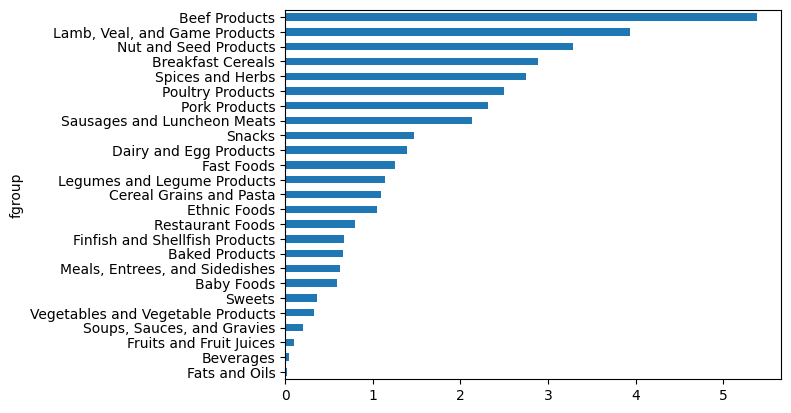

In [ ]:
result = ndata.groupby(["nutrient", "fgroup"])["value"].quantile(0.5)
pic_1 = result["Zinc, Zn"].sort_values().plot(kind="barh")

pic_1.figure.savefig("images/Zinc.png")
pic_1


Sử dụng phương pháp idxmax hoặc argmax Series để tìm ra loại thực phẩm nào có mật độ cao nhất trong mỗi chất dinh dưỡng:

In [ ]:
by_nutrient = ndata.groupby(["nutgroup", "nutrient"])
def get_maximum(x):
    return x.loc[x.value.idxmax()]
max_foods = by_nutrient.apply(get_maximum)[["value", "food"]]
# làm cho food nhỏ lại xíu
max_foods["food"] = max_foods["food"].str[:50]

C:\Users\biedu\AppData\Local\Temp\ipykernel_10032\870689507.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  max_foods = by_nutrient.apply(get_maximum)[["value", "food"]]


Vì DataFrame kết quả hơi lớn để hiển thị trong sách, nên đây chỉ là nhóm dinh dưỡng "Axit amin":

In [ ]:
max_foods.loc["Amino Acids"]["food"]

nutrient
Alanine                           Gelatins, dry powder, unsweetened
Arginine                               Seeds, sesame flour, low-fat
Aspartic acid                                   Soy protein isolate
Cystine                Seeds, cottonseed flour, low fat (glandless)
Glutamic acid                                   Soy protein isolate
Glycine                           Gelatins, dry powder, unsweetened
Histidine                Whale, beluga, meat, dried (Alaska Native)
Hydroxyproline    KENTUCKY FRIED CHICKEN, Fried Chicken, ORIGINA...
Isoleucine        Soy protein isolate, PROTEIN TECHNOLOGIES INTE...
Leucine           Soy protein isolate, PROTEIN TECHNOLOGIES INTE...
Lysine            Seal, bearded (Oogruk), meat, dried (Alaska Na...
Methionine                    Fish, cod, Atlantic, dried and salted
Phenylalanine     Soy protein isolate, PROTEIN TECHNOLOGIES INTE...
Proline                           Gelatins, dry powder, unsweetened
Serine            Soy protein isolate, 